TIỀN XỬ LÝ DỮ LIỆU

- Đọc file

In [1]:
import pandas as pd

duong_dan = "data/diabetes_prediction_dataset.csv"
df = pd.read_csv(duong_dan)

print("Kích thước dữ liệu:", df.shape)
display(df.head())
df.info()

Kích thước dữ liệu: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


- Kiểm tra dữ liệu hợp lệ

In [2]:
import pandas as pd
import numpy as np

# Đọc dữ liệu
df = pd.read_csv("data/diabetes_prediction_dataset.csv")

# Chuyển các giá trị "No info" thành NaN
df = df.replace(["No Info", "no info", "NO INFO", "N/A", "NA", "NaN", "nan", "None", "null"], np.nan)

# Kiểm tra dữ liệu thiếu
missing = df.isna().sum().sort_values(ascending=False)

print("Số lượng dữ liệu thiếu theo từng cột:")
print(missing[missing > 0])

# Kiểm tra dữ liệu trùng lặp
dup_rows = df.duplicated().sum()
print(f"\nSố dòng trùng lặp: {dup_rows}")

# Kiểm tra ngoại lệ (Outlier)
# Dùng phương pháp IQR: [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
numeric_cols = df.select_dtypes(include=[np.number]).columns

if len(numeric_cols) > 0:
    Q1 = df[numeric_cols].quantile(0.25)
    Q3 = df[numeric_cols].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_counts = ((df[numeric_cols] < lower_bound) | (df[numeric_cols] > upper_bound)).sum()
    outlier_counts = outlier_counts[outlier_counts > 0]

    print("\nSố lượng ngoại lệ theo cột:")
    print(outlier_counts)
    
else:
    print("\nKhông có cột số nào để kiểm tra ngoại lệ.")
missing_df = pd.DataFrame({
    "cột": missing.index,
    "số_dữ_liệu_thiếu": missing.values
})

print(missing_df)
    

Số lượng dữ liệu thiếu theo từng cột:
smoking_history    35816
dtype: int64

Số dòng trùng lặp: 3854

Số lượng ngoại lệ theo cột:
hypertension           7485
heart_disease          3942
bmi                    7086
HbA1c_level            1315
blood_glucose_level    2038
diabetes               8500
dtype: int64
                   cột  số_dữ_liệu_thiếu
0      smoking_history             35816
1               gender                 0
2                  age                 0
3         hypertension                 0
4        heart_disease                 0
5                  bmi                 0
6          HbA1c_level                 0
7  blood_glucose_level                 0
8             diabetes                 0


- Xử lý dữ liệu trùng

In [3]:
so_dong_truoc = len(df)
df = df.drop_duplicates().reset_index(drop=True)
so_dong_da_xoa = so_dong_truoc - len(df)

print(f"Số dòng trùng lặp đã xóa: {so_dong_da_xoa}")
print(f"Kích thước dữ liệu sau xử lý: {df.shape}")

Số dòng trùng lặp đã xóa: 3854
Kích thước dữ liệu sau xử lý: (96146, 9)


- Tách đặc trưng và nhãn

In [4]:
target_col = "diabetes"

X = df.drop(columns=[target_col])
y = df[target_col]

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
display(X.head())
display(y.head())

Kích thước X: (96146, 8)
Kích thước y: (96146,)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,Female,80.0,0,1,never,25.19,6.6,140
1,Female,54.0,0,0,NaN,27.32,6.6,80
2,Male,28.0,0,0,never,27.32,5.7,158
3,Female,36.0,0,0,current,23.45,5.0,155
4,Male,76.0,1,1,current,20.14,4.8,155


0    0
1    0
2    0
3    0
4    0
Name: diabetes, dtype: int64

- Chia train/test

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

Kích thước X_train: (76916, 8)
Kích thước X_test: (19230, 8)
Kích thước y_train: (76916,)
Kích thước y_test: (19230,)


- Xử lý dữ liệu thiếu

In [6]:
from sklearn.impute import SimpleImputer

# Tách cột số và cột phân loại
cot_so = X_train.select_dtypes(include="number").columns
cot_phan_loai = X_train.select_dtypes(exclude="number").columns

# Điền thiếu cột số bằng trung vị
imputer_so = SimpleImputer(strategy="median")
X_train.loc[:, cot_so] = imputer_so.fit_transform(X_train[cot_so])
X_test.loc[:, cot_so] = imputer_so.transform(X_test[cot_so])

# Điền thiếu cột phân loại bằng giá trị xuất hiện nhiều nhất
if len(cot_phan_loai) > 0:
    imputer_phan_loai = SimpleImputer(strategy="most_frequent")
    X_train.loc[:, cot_phan_loai] = imputer_phan_loai.fit_transform(
        X_train[cot_phan_loai]
    )
    X_test.loc[:, cot_phan_loai] = imputer_phan_loai.transform(
        X_test[cot_phan_loai]
    )

print("Số giá trị thiếu trong X_train:", X_train.isna().sum().sum())
print("Số giá trị thiếu trong X_test:", X_test.isna().sum().sum())

Số giá trị thiếu trong X_train: 0
Số giá trị thiếu trong X_test: 0


- Xử lý ngoại lệ

In [7]:
# Chỉ xử lý các đặc trưng liên tục, không bao gồm cột nhị phân
cot_lien_tuc = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

Q1_train = X_train[cot_lien_tuc].quantile(0.25)
Q3_train = X_train[cot_lien_tuc].quantile(0.75)
IQR_train = Q3_train - Q1_train

nguong_duoi = Q1_train - 1.5 * IQR_train
nguong_tren = Q3_train + 1.5 * IQR_train

# Giới hạn ngoại lệ ở cả tập train và test bằng ngưỡng từ tập train
X_train[cot_lien_tuc] = X_train[cot_lien_tuc].astype(float).clip(
    lower=nguong_duoi, upper=nguong_tren, axis=1
)
X_test[cot_lien_tuc] = X_test[cot_lien_tuc].astype(float).clip(
    lower=nguong_duoi, upper=nguong_tren, axis=1
)
X_test.loc[:, cot_lien_tuc] = X_test[cot_lien_tuc].clip(
    lower=nguong_duoi, upper=nguong_tren, axis=1
)

print("Số ngoại lệ còn lại trong X_train:",
      ((X_train[cot_lien_tuc] < nguong_duoi) |
       (X_train[cot_lien_tuc] > nguong_tren)).sum().sum())
print("Số ngoại lệ còn lại trong X_test:",
      ((X_test[cot_lien_tuc] < nguong_duoi) |
       (X_test[cot_lien_tuc] > nguong_tren)).sum().sum())

Số ngoại lệ còn lại trong X_train: 0
Số ngoại lệ còn lại trong X_test: 0


- Mã hóa dữ liệu phân loại

In [8]:
cot_phan_loai = cot_phan_loai.tolist()

X_train = pd.get_dummies(X_train, columns=cot_phan_loai, dtype=int)
X_test = pd.get_dummies(X_test, columns=cot_phan_loai, dtype=int)

# Đồng bộ các cột, cột không có trong một tập sẽ nhận giá trị 0
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Kích thước X_train sau mã hóa:", X_train.shape)
print("Kích thước X_test sau mã hóa:", X_test.shape)
display(X_train.head())

Kích thước X_train sau mã hóa: (76916, 14)
Kích thước X_test sau mã hóa: (19230, 14)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
76484,45.0,0,0,23.87,5.7,126.0,0,1,0,0,0,0,1,0
31572,64.0,0,0,33.03,4.0,126.0,1,0,0,0,0,1,0,0
92017,45.0,0,0,27.32,6.6,126.0,1,0,0,0,0,0,1,0
31616,44.0,1,0,28.86,4.8,80.0,0,1,0,0,0,0,1,0
94106,27.0,0,0,26.48,6.5,200.0,1,0,0,0,0,0,0,1


- Xử lý mất cân bằng

In [9]:
%pip install -q imbalanced-learn
from imblearn.over_sampling import RandomOverSampler

print("Phân bố lớp trước khi cân bằng:")
print(y_train.value_counts())

bo_tang_mau = RandomOverSampler(random_state=42)
X_train_can_bang, y_train_can_bang = bo_tang_mau.fit_resample(X_train, y_train)

print("\nPhân bố lớp sau khi cân bằng:")
print(y_train_can_bang.value_counts())
print("\nKích thước tập train sau cân bằng:", X_train_can_bang.shape)

Note: you may need to restart the kernel to use updated packages.
Phân bố lớp trước khi cân bằng:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Phân bố lớp sau khi cân bằng:
diabetes
0    70130
1    70130
Name: count, dtype: int64

Kích thước tập train sau cân bằng: (140260, 14)


- Lưu dữ liệu

In [11]:
from pathlib import Path

thu_muc = Path("data/processed")
thu_muc.mkdir(parents=True, exist_ok=True)

X_train_can_bang.to_csv(thu_muc / "X_train.csv", index=False)
y_train_can_bang.to_frame(name="diabetes").to_csv(
    thu_muc / "y_train.csv", index=False
)
X_test.to_csv(thu_muc / "X_test.csv", index=False)
y_test.to_frame(name="diabetes").to_csv(
    thu_muc / "y_test.csv", index=False
)

print("Đã lưu dữ liệu đã xử lý vào:", thu_muc)

Đã lưu dữ liệu đã xử lý vào: data\processed


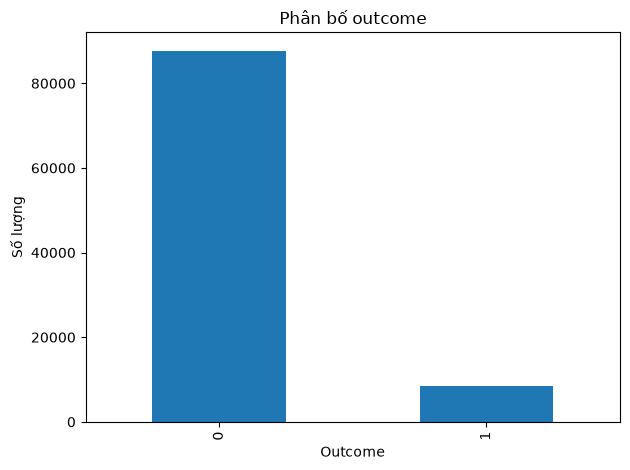

In [13]:
df["outcome"] = df["diabetes"]

ax = df["outcome"].value_counts().sort_index().plot(kind="bar")
import matplotlib.pyplot as plt

df["outcome"] = df["diabetes"]

ax = df["outcome"].value_counts().sort_index().plot(kind="bar")
ax.set(title="Phân bố outcome", xlabel="Outcome", ylabel="Số lượng")
plt.tight_layout()
plt.show()